<a href="https://colab.research.google.com/github/MNawfal24/MachineLearning/blob/main/Minggu11/MNawfalMA_JS11_P02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# Import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [7]:
# Create function to visualize SVM decision function
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Create grid for model evaluation
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot decision boundary and margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1.5, facecolors='none', edgecolors='black');

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

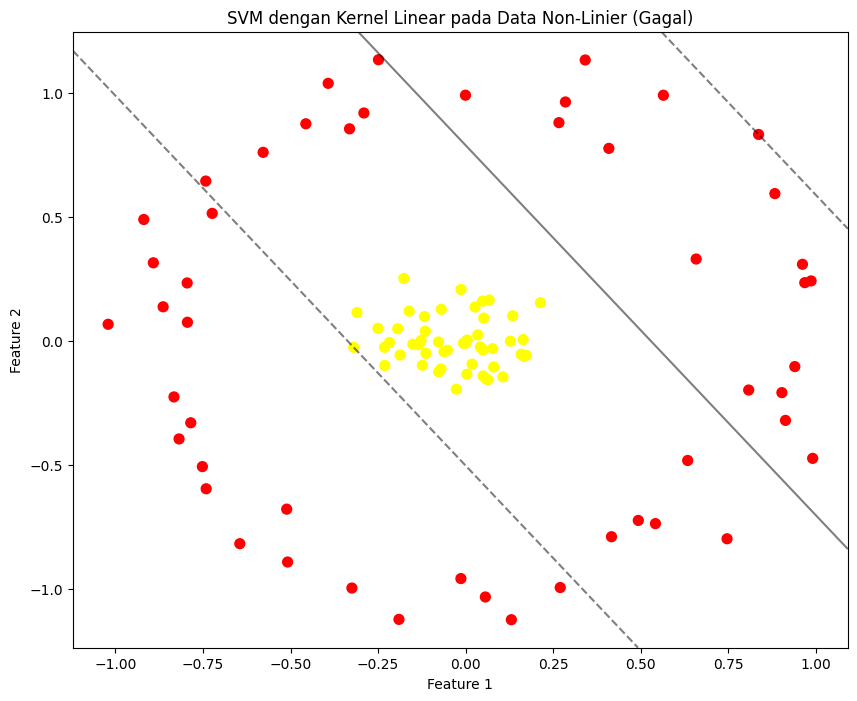

Perhatikan bahwa linear kernel tidak mampu memisahkan data dengan baik!


In [8]:
from sklearn.datasets import make_circles

# Create non-linearly separable data
X, y = make_circles(100, factor=.1, noise=.1)

# Fit with linear kernel (akan gagal)
clf_linear = SVC(kernel='linear').fit(X, y)

# Visualize
plt.figure(figsize=(10, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_linear, plot_support=False)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('SVM dengan Kernel Linear pada Data Non-Linier (Gagal)')
plt.show()

print('Perhatikan bahwa linear kernel tidak mampu memisahkan data dengan baik!')

In [9]:
# Fit dengan RBF kernel (kernel trick)
clf_rbf = SVC(kernel='rbf', C=1E6)
clf_rbf.fit(X, y)

print('RBF Model fitted successfully!')
print(f'Number of support vectors: {len(clf_rbf.support_vectors_)}')

RBF Model fitted successfully!
Number of support vectors: 8


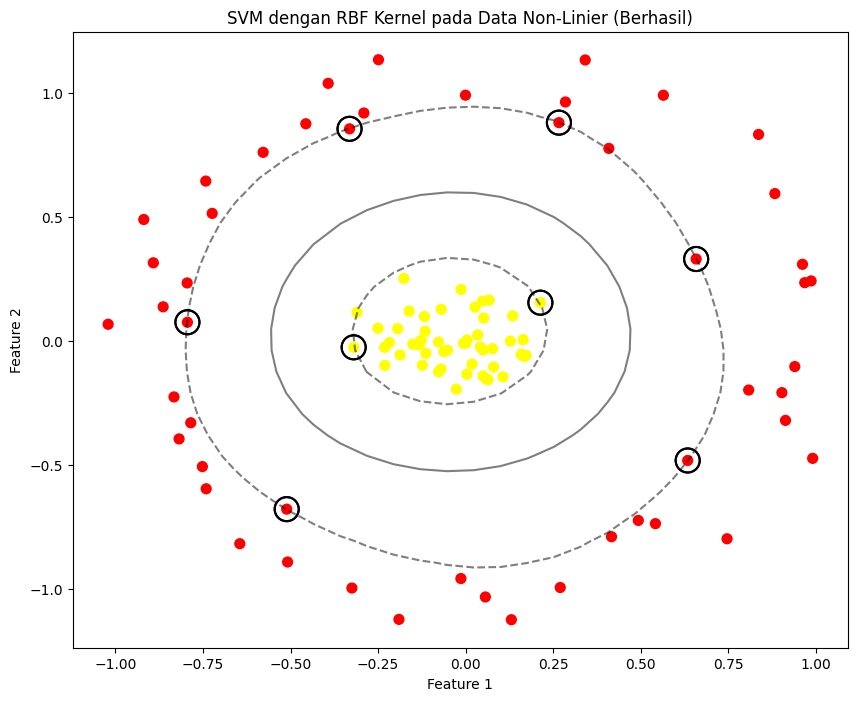

RBF kernel berhasil memisahkan data non-linier!


In [10]:
# Plot hasil RBF kernel
plt.figure(figsize=(10, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_rbf)
plt.scatter(clf_rbf.support_vectors_[:, 0], clf_rbf.support_vectors_[:, 1],
            s=300, lw=1.5, facecolors='none', edgecolors='black')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('SVM dengan RBF Kernel pada Data Non-Linier (Berhasil)')
plt.show()

print('RBF kernel berhasil memisahkan data non-linier!')